# Movie Recommendation System

This notebook demonstrates two complementary approaches to building a Movie Recommendation System using PyTorch on the MovieLens dataset:
1. **Collaborative Filtering** via Matrix Factorization
2. **Deep Learning Content-Based Filtering** using Two-Tower Neural Networks

We will cover dataset preprocessing, feature engineering, network definitions, customized optimization loops, and personalized recommendation generation.

In [876]:
import pandas as pd
import torch
torch.manual_seed(42)
device= "cuda" if torch.cuda.is_available() else "cpu"

## 1. Environment and Library Setup

We import the essential modules for numerical computations, data manipulation, deep learning, and evaluation, and check the available system device for model acceleration.

In [877]:
print(f"device:{device}")

device:cuda


## 2. Exploratory Data Analysis (EDA)

We load and inspect raw metadata from the MovieLens collection, including links, movies, and tags, to understand the data schema and check for available feature attributes.

In [878]:
links_df=pd.read_csv("Movies lens/links.csv")
links_df

,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0
...,...,...,...
9737,193581,5476944,432131.0
9738,193583,5914996,445030.0
9739,193585,6397426,479308.0
9740,193587,8391976,483455.0


In [879]:
movies_df=pd.read_csv("Movies lens/movies.csv")
movies_df

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy
...,...,...,...
9737,193581,Black Butler: Book of the Atlantic (2017),Action|Animation|Comedy|Fantasy
9738,193583,No Game No Life: Zero (2017),Animation|Comedy|Fantasy
9739,193585,Flint (2017),Drama
9740,193587,Bungo Stray Dogs: Dead Apple (2018),Action|Animation


In [880]:
links_df=pd.read_csv("Movies lens/links.csv")
links_df

,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0
...,...,...,...
9737,193581,5476944,432131.0
9738,193583,5914996,445030.0
9739,193585,6397426,479308.0
9740,193587,8391976,483455.0


In [881]:
tags_df=pd.read_csv("Movies lens/tags.csv")
tags_df


,userId,movieId,tag,timestamp
0,2,60756,funny,1445714994
1,2,60756,Highly quotable,1445714996
2,2,60756,will ferrell,1445714992
3,2,89774,Boxing story,1445715207
4,2,89774,MMA,1445715200
...,...,...,...,...
3678,606,7382,for katie,1171234019
3679,606,7936,austere,1173392334
3680,610,3265,gun fu,1493843984
3681,610,3265,heroic bloodshed,1493843978


## 3. Data Preprocessing and Matrix Creation

To construct our recommendation models, we perform the following pipeline:
1. Filter out movies with fewer than 10 ratings to minimize sparsity issues and noise.
2. Pivot the rating table into a clean User-Movie interaction matrix.
3. Replace missing values with 0 to indicate unrated titles.

In [882]:
ratings_df=pd.read_csv("Movies lens/ratings.csv")
ratings_df= ratings_df.groupby('movieId').filter(lambda x: len(x) >= 10)

In [883]:
rating_matrix=ratings_df.pivot(index="movieId",columns="userId",values="rating")
rating_matrix

userId,1,2,3,4,5,6,7,8,9,10,...,601,602,603,604,605,606,607,608,609,610
movieId,,,,,,,,,,,,,,,,,,,,,
1,4.0,NaN,NaN,NaN,4.0,NaN,4.5,NaN,NaN,NaN,...,4.0,NaN,4.0,3.0,4.0,2.5,4.0,2.5,3.0,5.0
2,NaN,NaN,NaN,NaN,NaN,4.0,NaN,4.0,NaN,NaN,...,NaN,4.0,NaN,5.0,3.5,NaN,NaN,2.0,NaN,NaN
3,4.0,NaN,NaN,NaN,NaN,5.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,5.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,3.0,NaN,NaN,NaN,NaN,NaN,NaN
6,4.0,NaN,NaN,NaN,NaN,4.0,NaN,NaN,NaN,NaN,...,NaN,3.0,4.0,3.0,NaN,NaN,NaN,NaN,NaN,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
174055,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
176371,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
177765,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,4.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [884]:
rating_matrix.fillna(0,inplace=True)
rating_matrix

userId,1,2,3,4,5,6,7,8,9,10,...,601,602,603,604,605,606,607,608,609,610
movieId,,,,,,,,,,,,,,,,,,,,,
1,4.0,0.0,0.0,0.0,4.0,0.0,4.5,0.0,0.0,0.0,...,4.0,0.0,4.0,3.0,4.0,2.5,4.0,2.5,3.0,5.0
2,0.0,0.0,0.0,0.0,0.0,4.0,0.0,4.0,0.0,0.0,...,0.0,4.0,0.0,5.0,3.5,0.0,0.0,2.0,0.0,0.0
3,4.0,0.0,0.0,0.0,0.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0
6,4.0,0.0,0.0,0.0,0.0,4.0,0.0,0.0,0.0,0.0,...,0.0,3.0,4.0,3.0,0.0,0.0,0.0,0.0,0.0,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
174055,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
176371,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
177765,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,4.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 4. Model Parameter Initialization

We set the latent space dimension to 25 and instantiate parameters for matrix factorization:
- **W**: User latent matrix
- **b**: User bias vectors
- **X**: Movie latent matrix

In [885]:
n_movies_features=25
W=(torch.randn((rating_matrix.shape[1],n_movies_features),device=device)*0.01).requires_grad_(True)
b=(torch.zeros(size=(1,rating_matrix.shape[1]),device=device,requires_grad=True))
X=(torch.rand((rating_matrix.shape[0],n_movies_features),device=device)*0.01).requires_grad_(True)
W.shape,b.shape,X.shape

(torch.Size([610, 25]), torch.Size([1, 610]), torch.Size([2269, 25]))

In [886]:
Y=torch.tensor(rating_matrix.to_numpy(),dtype=torch.float32,device=device)
Y

tensor([[4.0000, 0.0000, 0.0000,  ..., 2.5000, 3.0000, 5.0000],
        [0.0000, 0.0000, 0.0000,  ..., 2.0000, 0.0000, 0.0000],
        [4.0000, 0.0000, 0.0000,  ..., 2.0000, 0.0000, 0.0000],
        ...,
        [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000]],
       device='cuda:0')

In [887]:
R=(Y!=0).int()
R_train=((torch.randn(size=Y.shape,device=device)<=0.8) & (R==1)).int()
R_test=R-R_train
R.shape,R_train.shape,R_test.shape

(torch.Size([2269, 610]), torch.Size([2269, 610]), torch.Size([2269, 610]))

## 5. Cost Function and Performance Metrics

We define our customized training loss function using Mean Squared Error (MSE) with L2 regularization penalty, alongside a separate helper function to calculate Root Mean Squared Error (RMSE) over valid ratings.

In [888]:
def Compute_Loss(W,b,X,R,Y,lambda_):
  cost=(((X@W.T+b-Y)**2)*R).sum()*0.5+0.5*lambda_*((W**2).sum()+(X**2).sum())
  return cost


In [889]:
optim=torch.optim.Adam([W,b,X],lr=0.1)

In [890]:
def rmse(pred, Y, R):
    R = R.bool()
    return (((pred - Y) ** 2)[R]).mean().sqrt().item()

## 6. Training Loop Definition

We define the full iterative optimization loop that executes backpropagation, updates embeddings using the Adam optimizer, and logs validation losses over epochs.

In [891]:
def Train_model(W,b,X,R_train,R_test,Y,lambda_,n_epochs,optim):
  Test_rmses=[]
  Train_rmses=[]
  Train_losses=[]
  Test_losses=[]
  for epoch in range(n_epochs):
    optim.zero_grad()
    train_loss=Compute_Loss(W,b,X,R_train,Y,lambda_)
    train_loss.backward()
    optim.step()
    Train_losses.append(train_loss.item())
    with torch.no_grad():
      test_loss=Compute_Loss(W,b,X,R_test,Y,lambda_)
      Test_losses.append(test_loss.item())
      preds=X@W.T+b
      train_rmse=rmse(preds,Y,R_train)
      Train_rmses.append(train_rmse)
      test_rmse=rmse(preds,Y,R_test)
      Test_rmses.append(test_rmse)
    if (epoch+1)%10==0:
      print(f"epoch {epoch+1} / {n_epochs} : Train loss = {train_loss.item():0.2f} | Train rmse = {train_rmse:.2f} | Test loss = {test_loss.item():0.2f} | Test rmse = {test_rmse:.2f} ")

  return Train_losses, Test_losses,Train_rmses,Test_rmses



## 7. Collaborative Filtering Model Training

We initiate model optimization using a learning rate of 0.1 and run the loop for 200 epochs, tracking convergence behavior.

In [892]:
Train_losses, Test_losses,Train_rmses,Test_rmses=Train_model(W,b,X,R_train,R_test,Y,20,200,optim)

epoch 10 / 200 : Train loss = 148646.09 | Train rmse = 1.17 | Test loss = 80536.36 | Test rmse = 1.21 
epoch 20 / 200 : Train loss = 75225.34 | Train rmse = 0.98 | Test loss = 48547.09 | Test rmse = 1.03 
epoch 30 / 200 : Train loss = 59708.54 | Train rmse = 0.98 | Test loss = 38249.94 | Test rmse = 1.03 
epoch 40 / 200 : Train loss = 51861.74 | Train rmse = 0.87 | Test loss = 34648.05 | Test rmse = 0.92 
epoch 50 / 200 : Train loss = 45062.52 | Train rmse = 0.86 | Test loss = 28001.83 | Test rmse = 0.91 
epoch 60 / 200 : Train loss = 39880.08 | Train rmse = 0.84 | Test loss = 24011.82 | Test rmse = 0.89 
epoch 70 / 200 : Train loss = 35848.26 | Train rmse = 0.82 | Test loss = 20663.34 | Test rmse = 0.87 
epoch 80 / 200 : Train loss = 32628.74 | Train rmse = 0.81 | Test loss = 17791.88 | Test rmse = 0.87 
epoch 90 / 200 : Train loss = 30089.37 | Train rmse = 0.81 | Test loss = 15545.80 | Test rmse = 0.86 
epoch 100 / 200 : Train loss = 28127.57 | Train rmse = 0.80 | Test loss = 13745.3

## 8. Performance Evaluation

We visualize training and testing metrics using Matplotlib to track convergence curves and detect potential overfitting.

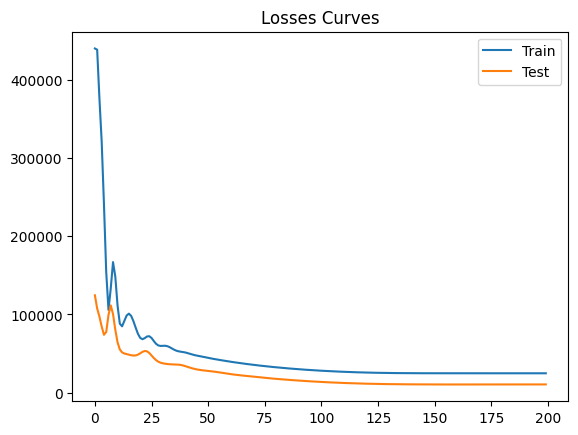

In [893]:
import matplotlib.pyplot as plt
plt.plot(Train_losses,label="Train")
plt.plot(Test_losses,label="Test")
plt.title("Losses Curves")
plt.legend()
plt.show()

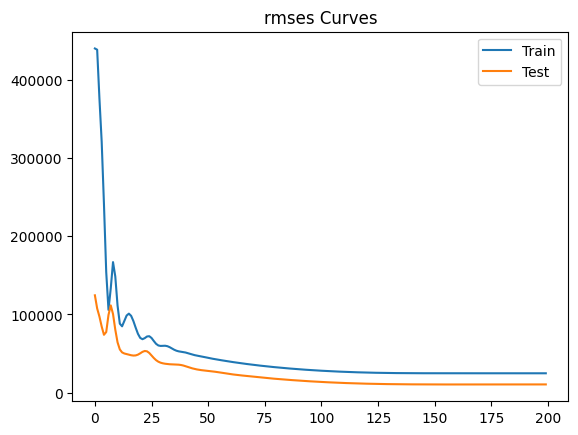

In [894]:
import matplotlib.pyplot as plt
plt.plot(Train_losses,label="Train")
plt.plot(Test_losses,label="Test")
plt.title("rmses Curves")
plt.legend()
plt.show()

## 9. Movie Similarity Finder

This robust similarity engine finds similar items based on cosine similarity of the learned movie embeddings. It handles three edge cases:
- **No Match**: Provides closest string distance alternatives using difflib.
- **Multiple Matches**: Automatically falls back to the most popular/highly rated candidate.
- **Exact Match**: Seamlessly outputs top similar movies exceeding a minimum rating count threshold.

In [895]:
import torch.nn.functional as F
import difflib
import numpy as np
import pandas as pd
import torch

# 1. Recover row -> movieId matching your rating_matrix index
movie_ids = rating_matrix.index.to_numpy()
assert len(movie_ids) == X.shape[0]

# 2. Row -> title
movies_df_loaded = pd.read_csv("Movies lens/movies.csv")
titles = pd.Series(movies_df_loaded.set_index("movieId").loc[movie_ids, "title"].values)

# 3. Normalized movie vectors + number of training ratings per movie
Xn = F.normalize(X.detach().cpu(), dim=1)
n_train = R_train.sum(1).cpu().numpy()

# 4. Search function
def similar_movies(query, k=10, min_ratings=20):
    matches = titles[titles.str.contains(query, case=False, regex=False)]
    if matches.empty:
        close = difflib.get_close_matches(query, titles.tolist(), n=5, cutoff=0.4)
        print(f"No match for '{query}'." + (f" Did you mean: {close}" if close else ""))
        return
    idx = matches.index[np.argmax(n_train[matches.index])]   # most-rated match
    if len(matches) > 1:
        print(f"{len(matches)} matches, using: {titles[idx]}")

    sims = Xn @ Xn[idx]
    sims[idx] = -2                                           # exclude itself
    sims[torch.from_numpy(n_train < min_ratings)] = -2       # skip weak vectors
    top = sims.topk(k)
    print(f"\nMovies similar to: {titles[idx]}")
    return pd.DataFrame({
        "title": titles.iloc[top.indices.numpy()].values,
        "similarity": top.values.numpy().round(3),
        "n_ratings": n_train[top.indices.numpy()].astype(int),
    })

# Test the robust search
similar_movies("Toy Story", k=10, min_ratings=10)

3 matches, using: Toy Story (1995)

Movies similar to: Toy Story (1995)


,title,similarity,n_ratings
0,Aladdin (1992),0.966,145
1,Back to the Future (1985),0.885,134
2,Mulan (1998),0.881,39
3,"Name of the Rose, The (Name der Rose, Der) (1986)",0.878,13
4,Contagion (2011),0.849,12
5,Billy Elliot (2000),0.843,29
6,Monsters University (2013),0.842,12
7,Love Actually (2003),0.838,47
8,Some Like It Hot (1959),0.832,31
9,King Kong (1933),0.824,20


## 10. Matrix Factorization Inference for New Users

We register new users using a dictionary of historical preferences. By freezing the learned movie matrix and utilizing analytical linear algebra optimization, we solve for the new user's specific embedding vector to generate instant, personalized recommendations.

In [896]:
Xc = X.detach().cpu()

def find_movie(query):
    """Row index for a title: exact match first, else most-rated substring match, else None."""
    exact = titles[titles.str.lower() == query.lower()]
    if not exact.empty:
        return exact.index[0]
    m = titles[titles.str.contains(query, case=False, regex=False)]
    if m.empty:
        return None
    return m.index[np.argmax(n_train[m.index])]

def keep_available(ratings, verbose=True):
    ok = {}
    for name, rating in ratings.items():
        if find_movie(name) is None:
            if verbose:
                print("not in model, skipped:", name)
        else:
            ok[name] = rating
    return ok

def recommend_for_new_user(my_ratings, lambda_, k=10, min_ratings=100, verbose=False):
    # 1. map titles -> rows
    idx, y = [], []
    for name, rating in my_ratings.items():
        i = find_movie(name)
        if i is None:
            print("not in model, skipped:", name)
            continue
        if verbose:
            print(f"{name!r} -> {titles[i]}  (rating {rating})")
        idx.append(int(i)); y.append(rating)
    idx = torch.tensor(idx)
    y = torch.tensor(y, dtype=torch.float32)

    # 2. solve for [w, b] with X frozen (bias is not regularized, like your loss)
    A = torch.cat([Xc[idx], torch.ones(len(idx), 1)], dim=1)
    reg = torch.diag(torch.tensor([float(lambda_)] * Xc.shape[1] + [0.0]))
    theta = torch.linalg.solve(A.T @ A + reg, A.T @ y)
    w, b_new = theta[:-1], theta[-1]

    # 3. predict every movie; hide rated and weakly trained ones
    pred = (Xc @ w + b_new).clamp(0.5, 5)
    pred[idx] = -1
    pred[torch.from_numpy(n_train < min_ratings)] = -1
    top = pred.topk(k)

    return pd.DataFrame({
        "title": titles.iloc[top.indices.numpy()].values,
        "predicted_rating": top.values.numpy().round(2),
        "n_ratings": n_train[top.indices.numpy()].astype(int),
    })

# Test the new solver recommendation engine
my_ratings = {
    # Sci-fi / fantasy
    "Lord of the Rings: The Fellowship of the Ring, The (2001)": 5.0,
    "Lord of the Rings: The Two Towers, The (2002)": 5.0,
    "Lord of the Rings: The Return of the King, The (2003)": 5.0,
    "Inception (2010)": 4.8,
    "Blade Runner (1982)": 3.5,
    "Interstellar (2014)": 5.0,
    "Back to the Future (1985)": 4.5,
    "Jurassic Park (1993)": 4.0,

    # Harry Potter (all 8)
    "Harry Potter and the Sorcerer's Stone": 5.0,
    "Harry Potter and the Chamber of Secrets": 5.0,
    "Harry Potter and the Prisoner of Azkaban": 5.0,
    "Harry Potter and the Goblet of Fire": 5.0,
    "Harry Potter and the Order of the Phoenix": 5.0,
    "Harry Potter and the Half-Blood Prince": 5.0,
    "Harry Potter and the Deathly Hallows: Part 1": 5.0,
    "Harry Potter and the Deathly Hallows: Part 2": 5.0,

    # Action / superhero / adventure
    "Dark Knight, The (2008)": 5.0,
    "Batman Begins (2005)": 4.5,
    "Iron Man (2008)": 4.5,
    "Avengers, The (2012)": 4.7,
    "Pirates of the Caribbean: The Curse of the Black Pearl (2003)": 4.5,
    "Gladiator (2000)": 4.7,
    "Saving Private Ryan (1998)": 4.9,

    # Spider-Man
    "Spider-Man (2002)": 4.3,
    "Spider-Man 2 (2004)": 4.6,
    "Spider-Man 3 (2007)": 3.3,
    "Amazing Spider-Man, The (2012)": 4.2,

    # Crime / drama classics
    "Fight Club (1999)": 5.0,
    "Pulp Fiction (1994)": 5.0,
    "Shawshank Redemption, The (1994)": 5.0,
    "Forrest Gump (1994)": 5.0,
    "Godfather, The (1972)": 5.0,
    "Silence of the Lambs, The (1991)": 5.0,
    "Se7en": 4.5,

    # Romance / drama
    "Titanic (1997)": 4.2,
    "Notebook, The (2004)": 4.5,
    "You've Got Mail (1998)": 4.7,
    "Eternal Sunshine of the Spotless Mind (2004)": 4.8,
    "Pride & Prejudice (2005)": 4.7,
    "(500) Days of Summer (2009)": 4.2,
    "Atonement (2007)": 3.9,
    "Fault in Our Stars, The (2014)": 4.5,
    "Devil Wears Prada, The (2006)": 4.4,

    # Animation
    "Toy Story (1995)": 5.0,
    "Toy Story 2 (1999)": 4.8,
    "Toy Story 3 (2010)": 4.9,
    "Finding Nemo (2003)": 5.0,
    "Lion King, The (1994)": 5.0,
    "Incredibles, The (2004)": 4.5,
    "Monsters, Inc. (2001)": 4.7,
    "Up (2009)": 5.0,
    "WALL·E (2008)": 4.9,
    "Ratatouille (2007)": 5.0,
    "How to Train Your Dragon (2010)": 4.6,
    "Kung Fu Panda (2008)": 4.7,
    "Tangled (2010)": 4.4,
    "Aladdin (1992)": 4.7,
    "Beauty and the Beast (1991)": 3.5,
    "Ice Age (2002)": 4.1,
    "Cars (2006)": 4.6,
    "Inside Out (2015)": 4.5,
    "Mulan (1998)": 4.0,
}

recommend_for_new_user(my_ratings, lambda_=20, k=10, min_ratings=50, verbose=True)

'Lord of the Rings: The Fellowship of the Ring, The (2001)' -> Lord of the Rings: The Fellowship of the Ring, The (2001)  (rating 5.0)
'Lord of the Rings: The Two Towers, The (2002)' -> Lord of the Rings: The Two Towers, The (2002)  (rating 5.0)
'Lord of the Rings: The Return of the King, The (2003)' -> Lord of the Rings: The Return of the King, The (2003)  (rating 5.0)
'Inception (2010)' -> Inception (2010)  (rating 4.8)
'Blade Runner (1982)' -> Blade Runner (1982)  (rating 3.5)
'Interstellar (2014)' -> Interstellar (2014)  (rating 5.0)
'Back to the Future (1985)' -> Back to the Future (1985)  (rating 4.5)
'Jurassic Park (1993)' -> Jurassic Park (1993)  (rating 4.0)
"Harry Potter and the Sorcerer's Stone" -> Harry Potter and the Sorcerer's Stone (a.k.a. Harry Potter and the Philosopher's Stone) (2001)  (rating 5.0)
'Harry Potter and the Chamber of Secrets' -> Harry Potter and the Chamber of Secrets (2002)  (rating 5.0)
'Harry Potter and the Prisoner of Azkaban' -> Harry Potter and the

,title,predicted_rating,n_ratings
0,Schindler's List (1993),4.73,171
1,Star Wars: Episode IV - A New Hope (1977),4.73,203
2,"Usual Suspects, The (1995)",4.73,168
3,Star Wars: Episode V - The Empire Strikes Back...,4.71,165
4,American Beauty (1999),4.70,158
5,"Matrix, The (1999)",4.70,220
6,"Princess Bride, The (1987)",4.70,106
7,"Amelie (Fabuleux destin d'Amélie Poulain, Le) ...",4.70,91
8,Raiders of the Lost Ark (Indiana Jones and the...,4.70,156
9,Monty Python and the Holy Grail (1975),4.70,106


## 11. Deep Learning Content-Based Filtering (Two-Tower Architecture)

We construct two separate deep feed-forward neural networks that map user preferences and movie descriptors into a shared latent vector space of dimension $L$:
- **User Tower**: Maps user multi-genre preference profiles to a latent vector.
- **Movie Tower**: Maps movie multi-hot genre descriptors to a latent vector.

The final estimated score is computed via the dot product between these two latent vectors:
$$\hat{y}_{u,m} = v_u \cdot v_m$$

In [897]:
import torch
import torch.nn as nn
import pandas as pd
import numpy as np
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.model_selection import train_test_split

ratings_np = rating_matrix.to_numpy().astype(np.float32)      # (n_movies, n_users)
movie_idx, user_idx = np.where(ratings_np > 0)                # one entry per known rating
y_all = ratings_np[movie_idx, user_idx]

# --- 1. Split the ratings ONCE (indices), so features and labels stay aligned ---
idx_train, idx_test = train_test_split(
    np.arange(len(y_all)), train_size=0.80, shuffle=True, random_state=1
)

# --- 2. Movie features: genre multi-hot (already 0/1, no scaling needed) ---
movies_df_loaded = pd.read_csv("Movies lens/movies.csv") \
                     .set_index("movieId").loc[rating_matrix.index]
mlb = MultiLabelBinarizer()
G = mlb.fit_transform(movies_df_loaded["genres"].str.split("|")).astype(np.float32)  # (n_movies, n_genres)

# --- 3. User features: average rating per genre, from TRAIN ratings only ---
train_mask = np.zeros_like(ratings_np)
train_mask[movie_idx[idx_train], user_idx[idx_train]] = 1.0

sums   = G.T @ (ratings_np * train_mask)                      # (n_genres, n_users)
counts = G.T @ train_mask
user_features_np = np.divide(sums, counts, out=np.zeros_like(sums), where=counts > 0).T
user_features_np = (user_features_np / 5.0).astype(np.float32)  # scale 0-5 ratings to 0-1

# --- 4. Pair features with each rating ---
item_all = G[movie_idx]                  # (n_ratings, n_genres)
user_all = user_features_np[user_idx]    # (n_ratings, n_genres)

# --- 5. Convert to tensors on the device ---
def T(a): return torch.tensor(a, dtype=torch.float32, device=device)

item_train, item_test = T(item_all[idx_train]), T(item_all[idx_test])
user_train, user_test = T(user_all[idx_train]), T(user_all[idx_test])
y_train,    y_test    = T(y_all[idx_train]),    T(y_all[idx_test])

print(f"Item features: {item_train.shape} | User features: {user_train.shape}")
print(f"Train size: {len(y_train)} | Test size: {len(y_test)}")

Item features: torch.Size([64892, 19]) | User features: torch.Size([64892, 19])
Train size: 64892 | Test size: 16224


In [898]:
class neural_nets(nn.Module):
  def __init__(self,n_outputs):
    super().__init__()
    self.User_NN=nn.Sequential(
        nn.Linear(19,256),
        nn.ReLU(),
        nn.Linear(256,128),
        nn.ReLU(),
        nn.Dropout(0.1),
        nn.Linear(128,64),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(64,n_outputs)

    )
    self.item_NN=nn.Sequential(
        nn.Linear(19,256),
        nn.ReLU(),
        nn.Linear(256,128),
        nn.ReLU(),
        nn.Dropout(0.1),
        nn.Linear(128,64),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(64,n_outputs)
    )
    self.init_weights()

  def init_weights(self):
     for net in (self.User_NN, self.item_NN):
            linears = [m for m in net if isinstance(m, nn.Linear)]
            for i, layer in enumerate(linears):
                if i < len(linears) - 1:
                    nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
                else:
                    nn.init.xavier_uniform_(layer.weight)
                nn.init.zeros_(layer.bias)

  def forward(self,user_features,item_features):
    Vu=self.User_NN(user_features)
    Vm=self.item_NN(item_features)
    return (Vu*Vm).sum(dim=1)


In [899]:
model=neural_nets(32)
criterion=nn.MSELoss()

In [900]:
optim = torch.optim.Adam(model.parameters(), lr=0.001)

In [901]:

def loss_fn(pred, y, model,lambda_):
    mse = criterion(pred, y)
    l2 = sum((p ** 2).sum() for name, p in model.named_parameters() if "weight" in name)
    return mse + 0.5 * lambda_ * l2

In [902]:
def train(n_epochs,model,item_train,user_train,y_train,y_test,item_test,user_test,lambda_):
  item_train, user_train, y_train = item_train.to(device), user_train.to(device), y_train.to(device)
  item_test, user_test, y_test = item_test.to(device), user_test.to(device), y_test.to(device)
  model=model.to(device)
  Train_losses, Test_losses, Train_rmses, Test_rmses = [], [], [], []
  for epoch in range(n_epochs):
    model.train(True)
    optim.zero_grad()
    train_preds=model(user_train,item_train)
    Loss=loss_fn(train_preds,y_train,model,lambda_)
    train_loss=Loss.item()
    Loss.backward()
    optim.step()
    model.eval()
    with torch.inference_mode():
       train_preds = model(user_train, item_train)   # after the step, so metrics match
       test_preds = model(user_test, item_test)
       train_mse = criterion(train_preds, y_train)
       test_mse = criterion(test_preds, y_test)
       train_rmse = train_mse.sqrt().item()
       test_rmse = test_mse.sqrt().item()
       train_loss = loss_fn(train_preds, y_train, model, lambda_).item()
       test_loss = loss_fn(test_preds, y_test, model, lambda_).item()

    Train_losses.append(train_loss)
    Test_losses.append(test_loss)
    Train_rmses.append(train_rmse)
    Test_rmses.append(test_rmse)
    if (epoch+1)%100==0:
      print(f"epoch {epoch+1} / {n_epochs} : Train loss = {train_loss:0.2f} | Train rmse = {train_rmse:.2f} | Test loss = {test_loss:0.2f} | Test rmse = {test_rmse:.2f} ")

  return Train_losses, Test_losses,Train_rmses,Test_rmses



In [903]:
Train_losses, Test_losses,Train_rmses,Test_rmses=train(2000,model,item_train,user_train
                                                       ,y_train,y_test
                                                       ,item_test,user_test,0)

epoch 100 / 2000 : Train loss = 1.05 | Train rmse = 1.02 | Test loss = 1.08 | Test rmse = 1.04 
epoch 200 / 2000 : Train loss = 0.96 | Train rmse = 0.98 | Test loss = 1.00 | Test rmse = 1.00 
epoch 300 / 2000 : Train loss = 0.91 | Train rmse = 0.96 | Test loss = 0.95 | Test rmse = 0.97 
epoch 400 / 2000 : Train loss = 0.90 | Train rmse = 0.95 | Test loss = 0.93 | Test rmse = 0.97 
epoch 500 / 2000 : Train loss = 0.81 | Train rmse = 0.90 | Test loss = 0.85 | Test rmse = 0.92 
epoch 600 / 2000 : Train loss = 0.81 | Train rmse = 0.90 | Test loss = 0.85 | Test rmse = 0.92 
epoch 700 / 2000 : Train loss = 0.78 | Train rmse = 0.89 | Test loss = 0.82 | Test rmse = 0.91 
epoch 800 / 2000 : Train loss = 0.77 | Train rmse = 0.88 | Test loss = 0.81 | Test rmse = 0.90 
epoch 900 / 2000 : Train loss = 0.77 | Train rmse = 0.88 | Test loss = 0.82 | Test rmse = 0.90 
epoch 1000 / 2000 : Train loss = 0.75 | Train rmse = 0.87 | Test loss = 0.80 | Test rmse = 0.90 
epoch 1100 / 2000 : Train loss = 0.74 |

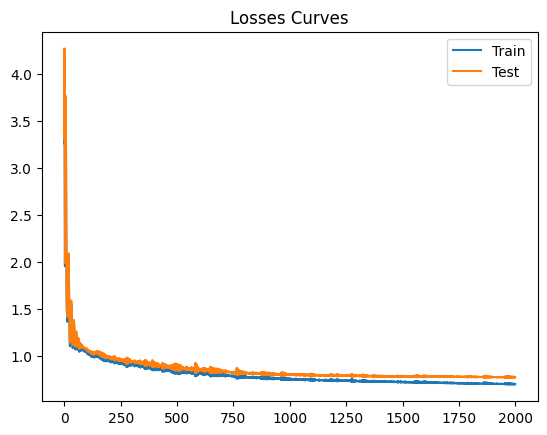

In [904]:
import matplotlib.pyplot as plt
plt.plot(Train_losses,label="Train")
plt.plot(Test_losses,label="Test")
plt.title("Losses Curves")
plt.legend()
plt.show()

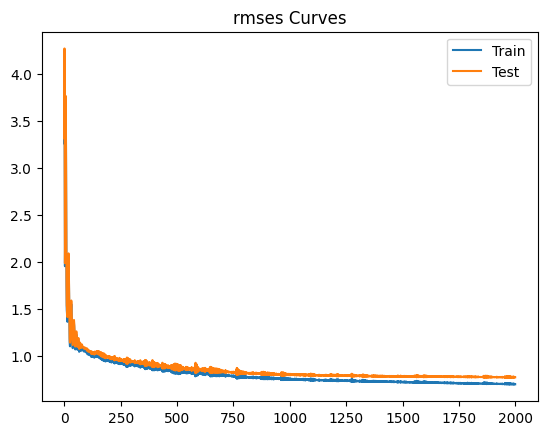

In [905]:
import matplotlib.pyplot as plt
plt.plot(Train_losses,label="Train")
plt.plot(Test_losses,label="Test")
plt.title("rmses Curves")
plt.legend()
plt.show()

## 12. Deep Learning Recommendations for Custom Profiles

Using the same inference pattern as our collaborative filtering method, we build a recommendation engine that dynamically processes a new user's ratings, computes their genre profile, passes it through the trained User Tower, and ranks all movies.

In [908]:
def dl_recommend_for_new_user(my_ratings, k=10, min_ratings=50):
    # Dynamically determine the active genre columns and number of features
    active_genres = mlb.classes_
    num_features = len(active_genres)

    # 1. Create a preference profile vector for this new user based on genres rated
    user_profile = np.zeros(num_features, dtype=np.float32)
    genre_counts = np.zeros(num_features, dtype=np.float32)

    # Resolve titles to row indices and construct user vector representation
    idx = []
    for name, rating in my_ratings.items():
        i = find_movie(name)
        if i is None:
            continue
        idx.append(i)
        genres_str = movies_df_loaded.iloc[i]['genres']
        for g_idx, genre in enumerate(active_genres):
            if genre in genres_str:
                user_profile[g_idx] += rating
                genre_counts[g_idx] += 1

    # Avoid dividing by zero and scale 0-5 ratings to 0-1
    genre_counts[genre_counts == 0] = 1.0
    user_profile = (user_profile / genre_counts) / 5.0

    # 2. Predict ratings using our trained User and Item towers
    model.eval()
    with torch.no_grad():
        u_tensor = torch.tensor(user_profile, dtype=torch.float32, device=device).unsqueeze(0)
        # G contains movie multi-hot profiles (2269, 19)
        item_tensor = torch.tensor(G, dtype=torch.float32, device=device)

        # Map both towers into latent representations
        Vu_pred = model.User_NN(u_tensor)  # shape: (1, latent_dim)
        Vm_pred = model.item_NN(item_tensor)  # shape: (N, latent_dim)

        preds = (Vu_pred * Vm_pred).sum(dim=1).cpu().numpy()

    # 3. Filter out already rated movies and weakly rated items
    for i in idx:
        preds[i] = -1

    preds[n_train < min_ratings] = -1
    top_indices = np.argsort(preds)[::-1][:k]

    return pd.DataFrame({
        "title": titles.iloc[top_indices].values,
        "predicted_rating": np.round(preds[top_indices], 2),
        "n_ratings": n_train[top_indices].astype(int)
    })

# Generate predictions for the custom user ratings profile
dl_recommend_for_new_user(my_ratings, k=10, min_ratings=50)

,title,predicted_rating,n_ratings
0,"Good, the Bad and the Ugly, The (Buono, il bru...",4.88,59
1,City of God (Cidade de Deus) (2002),4.83,63
2,Django Unchained (2012),4.82,55
3,Spirited Away (Sen to Chihiro no kamikakushi) ...,4.79,59
4,Psycho (1960),4.79,65
5,Reservoir Dogs (1992),4.77,97
6,"Usual Suspects, The (1995)",4.77,168
7,"Godfather: Part II, The (1974)",4.76,98
8,Catch Me If You Can (2002),4.76,89
9,American History X (1998),4.76,102
